# model training

In [1]:
import sys, os
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT)); os.chdir(ROOT)
import warnings; warnings.filterwarnings("ignore")
import pandas as pd, numpy as np
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)

In [2]:
from src import config
from src.data import load_clean_data, split_features_target
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
df = load_clean_data(); X, y = split_features_target(df)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=config.TEST_SIZE, stratify=y, random_state=config.RANDOM_STATE)
print(X_train.shape, X_test.shape, round(y_train.mean(), 3), round(y_test.mean(), 3))

(242, 13) (61, 13) 0.459 0.459


In [3]:
from src.features import build_pipeline, ClinicalFeatureBuilder, build_preprocessor
from sklearn.linear_model import LogisticRegression
pipe = build_pipeline(LogisticRegression(max_iter=2000, solver='liblinear'))
pipe

Pipeline(steps=[('features', ClinicalFeatureBuilder()),
                ('preprocess',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('impute',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scale',
                                                                   StandardScaler())]),
                                                  <function select_numeric at 0x10b25af20>),
                                                 ('cat',
                                                  Pipeline(steps=[('impute',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('onehot',
                                                                   OneHotEncoder(handle_unknown='ignore',
                                                                                 sparse_output=False))]),
                                                  <function select_categorical at 0x13d414b80>),
                                                 ('bin',
                                                  Pipeline(steps=[('impute',
                                                                   SimpleImputer(strategy='most_frequent'))]),
                                                  <function select_binary at 0x13d414c20>)],
                                   verbose_feature_names_out=False)),
                ('model',
                 LogisticRegression(max_iter=2000, solver='liblinear'))])

In [4]:
feats = ClinicalFeatureBuilder().fit_transform(X_train)
feats[['age','thalach','trestbps','hr_achieved_ratio','rate_pressure_index']].head()

,age,thalach,trestbps,hr_achieved_ratio,rate_pressure_index
180,48.0,166.0,124.0,0.965116,20.584
208,55.0,155.0,130.0,0.939394,20.150
167,54.0,159.0,132.0,0.957831,20.988
105,54.0,156.0,108.0,0.939759,16.848
297,57.0,123.0,140.0,0.754601,17.220


In [5]:
pre = build_preprocessor().fit(feats)
print(len(pre.get_feature_names_out()), 'model inputs:'); print(list(pre.get_feature_names_out()))

24 model inputs:
['age', 'trestbps', 'chol', 'thalach', 'oldpeak', 'ca', 'hr_achieved_ratio', 'rate_pressure_index', 'cp_1.0', 'cp_2.0', 'cp_3.0', 'cp_4.0', 'restecg_0.0', 'restecg_1.0', 'restecg_2.0', 'slope_1.0', 'slope_2.0', 'slope_3.0', 'thal_3.0', 'thal_6.0', 'thal_7.0', 'sex', 'fbs', 'exang']


default params, 5 fold cv

In [6]:
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.dummy import DummyClassifier
from src.evaluate import CV_SCORING
cv = StratifiedKFold(5, shuffle=True, random_state=config.RANDOM_STATE)
rows = {}
for name, est in {'majority': DummyClassifier(), 'logistic_regression': LogisticRegression(max_iter=2000, solver='liblinear'),
                  'random_forest': RandomForestClassifier(random_state=42), 'gradient_boosting': GradientBoostingClassifier(random_state=42)}.items():
    res = cross_validate(build_pipeline(est), X_train, y_train, cv=cv, scoring=CV_SCORING)
    rows[name] = {m: res[f'test_{m}'].mean() for m in CV_SCORING}
pd.DataFrame(rows).T.round(3)

,accuracy,precision,recall,f1,roc_auc
majority,0.541,0.000,0.000,0.000,0.500
logistic_regression,0.843,0.878,0.774,0.819,0.905
random_forest,0.822,0.844,0.756,0.794,0.873
gradient_boosting,0.798,0.780,0.783,0.780,0.855


tuned results from mlflow (python -m src.train)

In [7]:
import mlflow
mlflow.set_tracking_uri(config.MLFLOW_TRACKING_URI)
runs = mlflow.search_runs(experiment_names=[config.MLFLOW_EXPERIMENT], filter_string="tags.stage = 'tuning'")
cols = ['tags.mlflow.runName','metrics.cv_roc_auc_mean','metrics.cv_roc_auc_std','metrics.cv_accuracy_mean','metrics.cv_recall_mean','metrics.test_accuracy','metrics.test_precision','metrics.test_recall','metrics.test_roc_auc']
runs[cols].sort_values('metrics.cv_roc_auc_mean', ascending=False).round(3)

,tags.mlflow.runName,metrics.cv_roc_auc_mean,metrics.cv_roc_auc_std,metrics.cv_accuracy_mean,metrics.cv_recall_mean,metrics.test_accuracy,metrics.test_precision,metrics.test_recall,metrics.test_roc_auc
2,logistic_regression,0.907,0.019,0.855,0.801,0.869,0.812,0.929,0.961
1,random_forest,0.905,0.023,0.818,0.792,0.885,0.839,0.929,0.955
0,gradient_boosting,0.892,0.029,0.822,0.764,0.885,0.862,0.893,0.938
3,baseline_majority,0.500,0.000,0.541,0.000,0.541,0.000,0.000,0.500


In [8]:
trials = mlflow.search_runs(experiment_names=[config.MLFLOW_EXPERIMENT], filter_string="tags.stage = 'trial'")
print(len(trials), 'trials')
trials['family'] = trials['tags.mlflow.runName'].str.replace(r'-trial-\d+', '', regex=True)
trials.groupby(['family', 'params.engineered_features'])['metrics.cv_roc_auc_mean'].agg(['mean','max','count']).round(3)

112 trials


mean    max  count
family              params.engineered_features                     
baseline_majority   False                       0.500  0.500      1
gradient_boosting   False                       0.860  0.892     15
                    True                        0.873  0.892     10
logistic_regression False                       0.866  0.907     28
                    True                        0.864  0.907     28
random_forest       False                       0.892  0.905     15
                    True                        0.882  0.892     15

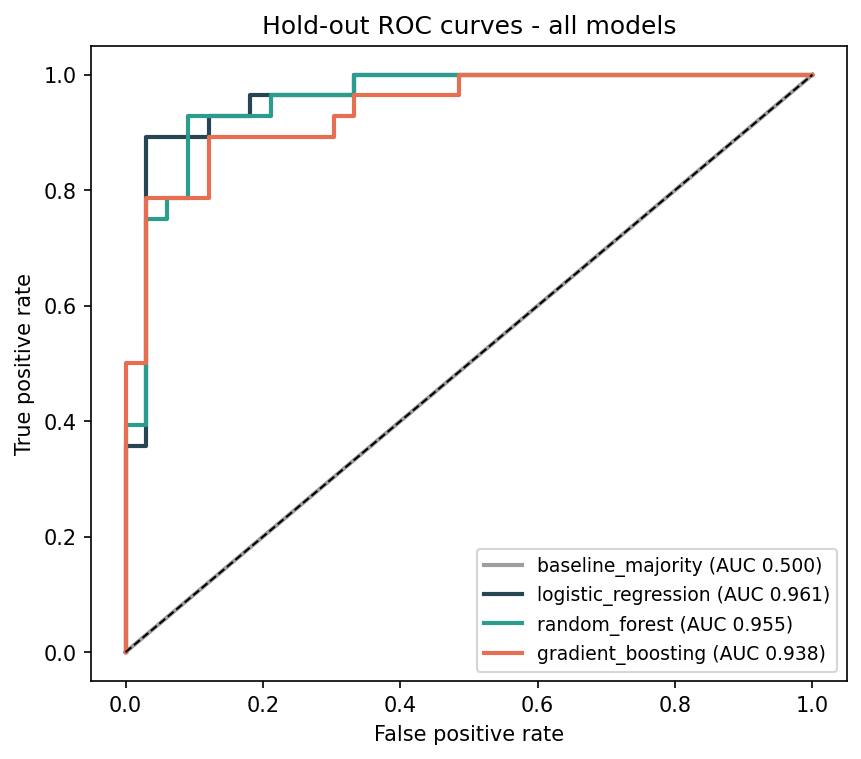

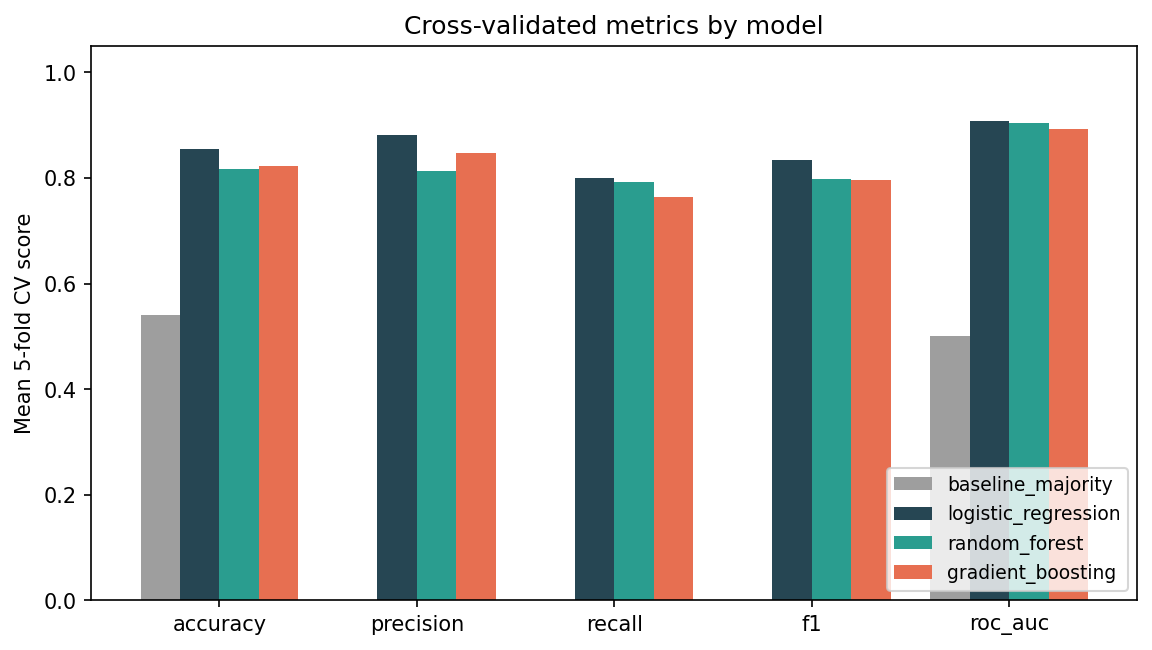

In [9]:
from IPython.display import Image, display
for f in ['09_roc_comparison.png', '10_cv_metric_comparison.png']:
    display(Image(filename=str(config.FIGURES_DIR / f), width=650))

In [10]:
import json
meta = json.loads(config.MODEL_METADATA_FILE.read_text())
{k: meta[k] for k in ['model_family','model_version','best_params','cv_metrics','test_metrics']}

{'model_family': 'logistic_regression',
 'model_version': '1.0.0+logistic_regression',
 'best_params': {'engineered_features': False,
  'C': 0.3,
  'class_weight': 'balanced',
  'penalty': 'l2'},
 'cv_metrics': {'cv_accuracy_mean': 0.8551870748299321,
  'cv_accuracy_std': 0.02704643119731138,
  'cv_precision_mean': 0.8818976789800589,
  'cv_precision_std': 0.07018786751261416,
  'cv_recall_mean': 0.8007905138339921,
  'cv_recall_std': 0.07503013293757824,
  'cv_f1_mean': 0.8341810854191829,
  'cv_f1_std': 0.032497545867502954,
  'cv_roc_auc_mean': 0.9074935531457269,
  'cv_roc_auc_std': 0.019275339510035346},
 'test_metrics': {'test_accuracy': 0.8688524590163934,
  'test_precision': 0.8125,
  'test_recall': 0.9285714285714286,
  'test_f1': 0.8666666666666667,
  'test_roc_auc': 0.9610389610389611,
  'test_pr_auc': 0.9488662439806965}}

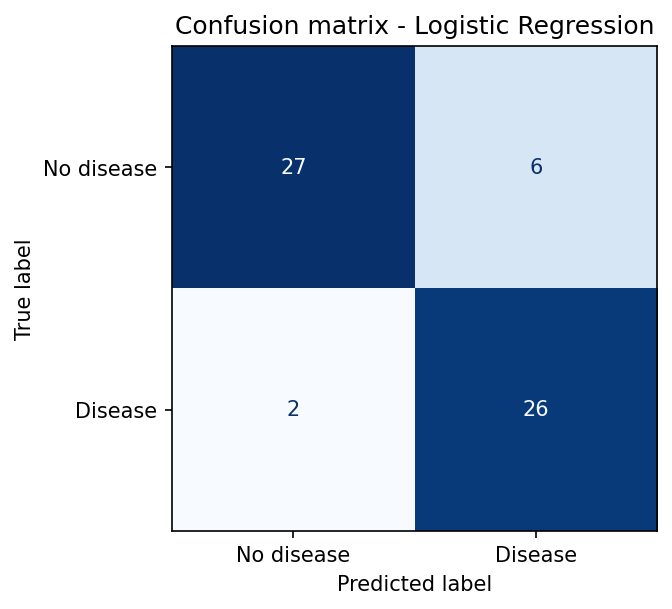

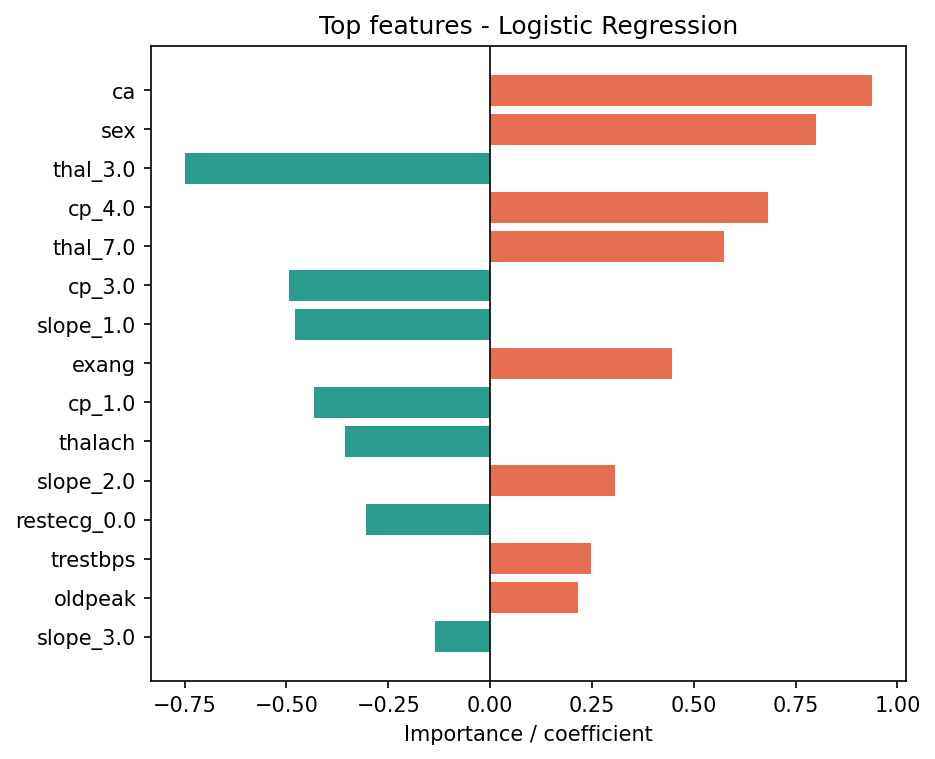

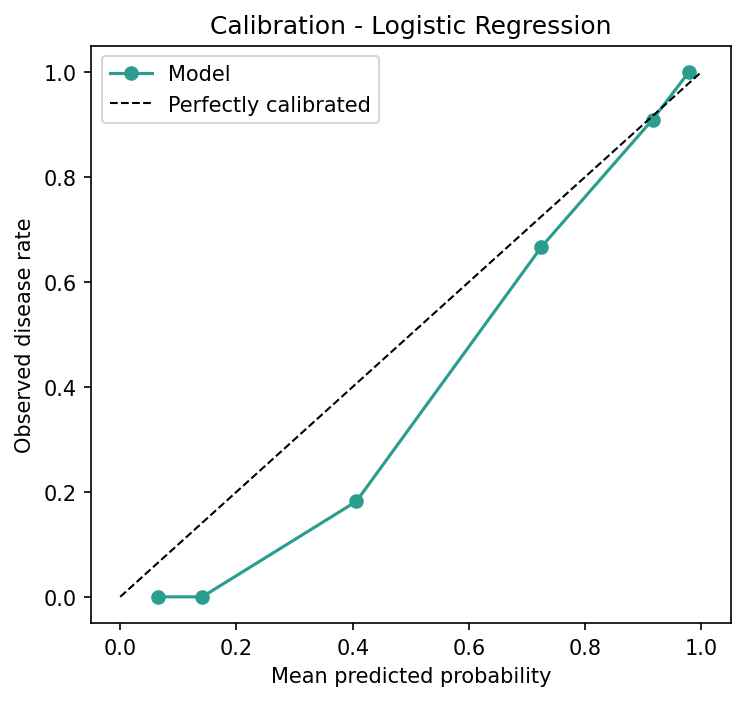

In [11]:
champ = meta['model_family']
for f in ['confusion_matrix.png', 'feature_importance.png', 'calibration.png']:
    display(Image(filename=str(config.FIGURES_DIR / 'models' / champ / f), width=480))

logistic regression picked (best cv roc auc 0.907, simple model). rf is close but more complex.